## Multi-Tool Calling with MAF and Microsoft Foundry

## Visual workflow

The agent is given two tools. It chooses Code Interpreter for computation and Microsoft Learn MCP for documentation retrieval, based on the query.

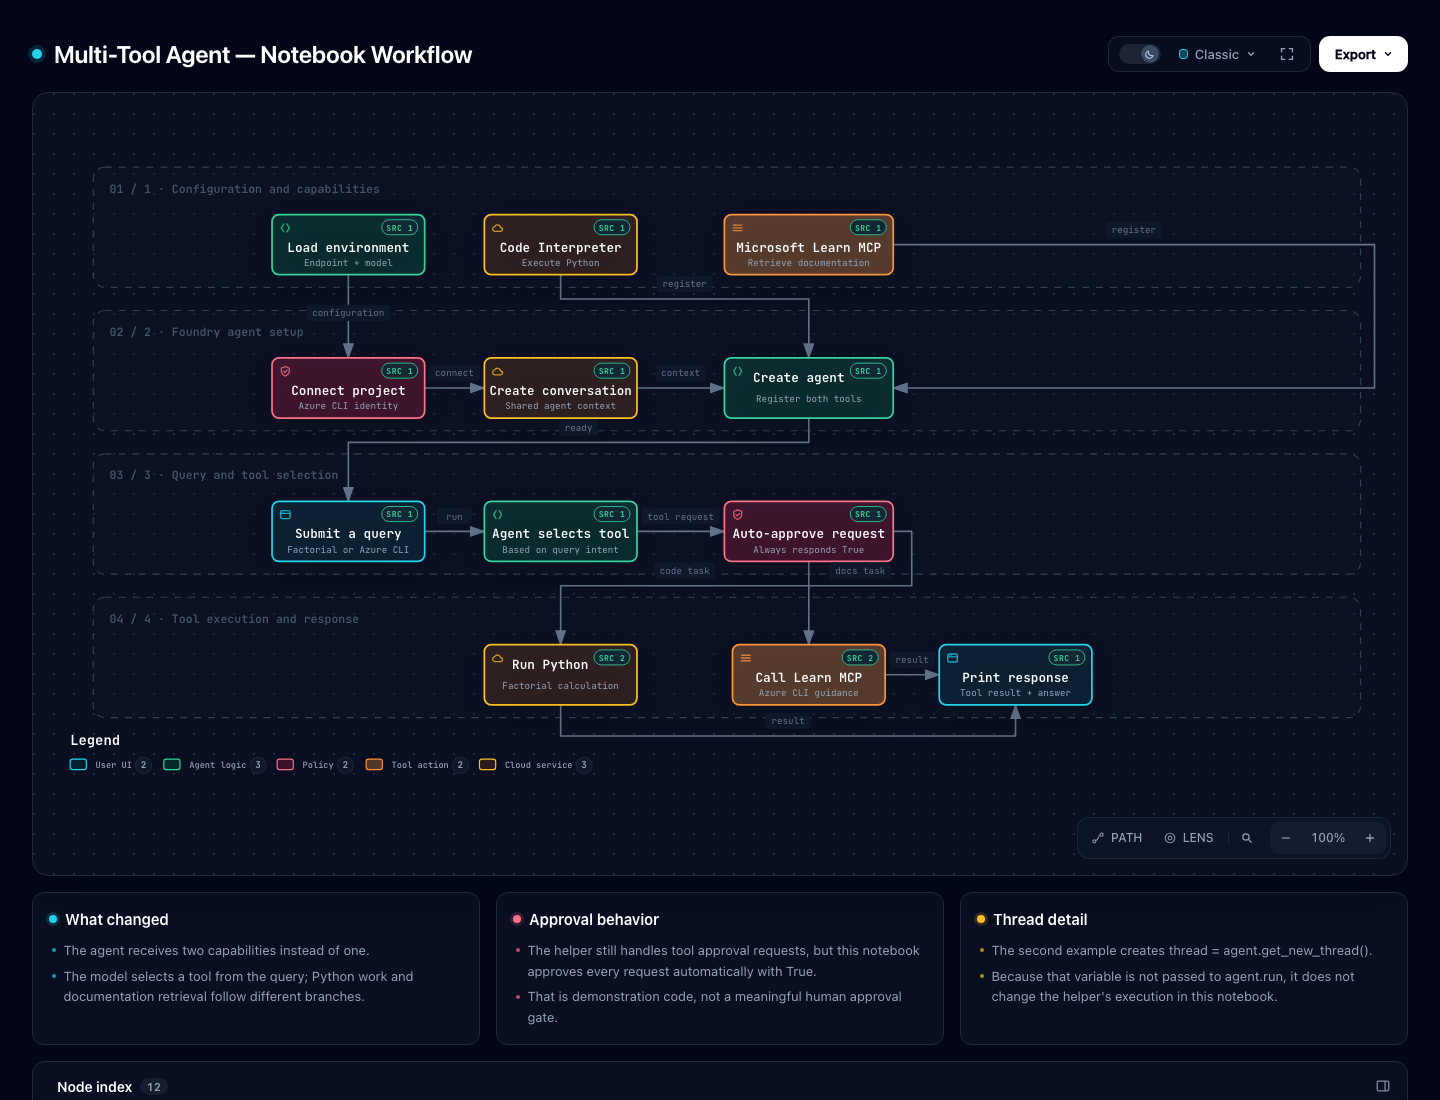

[Open the interactive Archify workflow](../../.archify/workflow-multiple-tools-notebook-20261030-155029/multiple-tools-workflow.html)

![mutliple-tools](./Assets/multiple-tools.png)

In [ ]:
# Install the pinned Agent Framework, environment loader, and Foundry project SDK.
# %pip installs into the environment used by this Jupyter kernel.
%pip install agent-framework==1.0.0b251209 python-dotenv azure-ai-projects==2.0.0b2

### Setting Up the Environment

In [ ]:
# Load the Foundry project endpoint and model deployment from environment configuration.
# This keeps project-specific values out of the notebook source.
import os
from dotenv import load_dotenv
from azure.core.credentials import AzureKeyCredential

load_dotenv()
project_endpoint = os.getenv("AI_FOUNDRY_PROJECT_ENDPOINT")
model = os.getenv("AI_FOUNDRY_DEPLOYMENT_NAME")

print("Project Endpoint: ", project_endpoint)
print("Model: ", model)

### Loading the Code Interpreter Tool

In [ ]:
# HostedCodeInterpreterTool gives the agent a managed environment for executing generated code.
# AgentRunResponse and ChatResponseUpdate are imported here but are not used later in this notebook.
from agent_framework import AgentRunResponse, ChatResponseUpdate, HostedCodeInterpreterTool

code_interpreter_tool = HostedCodeInterpreterTool()

### Loading the Hosted MCP Tool

In [ ]:
# HostedMCPTool describes the remote Microsoft Learn capability.
# Creating this object registers connection information; it does not call the MCP server yet.
from agent_framework import HostedMCPTool

ms_learn_mcp_tool = HostedMCPTool(
    name = "Microsoft Learn MCP Tool",
    url = "https://learn.microsoft.com/api/mcp"
)

### Creating our Mutli-Tooled Agent

In [ ]:
# Create one agent that can choose between Code Interpreter and Microsoft Learn MCP.
from agent_framework.azure import AzureAIClient
from azure.identity.aio import AzureCliCredential
from azure.ai.projects.aio import AIProjectClient

# async def allows setup to pause while Foundry creates remote resources.
async def create_multi_tool_agent():
    # Reuse the identity authenticated through the Azure CLI.
    credential = AzureCliCredential()
    
    # creating the Foundry Project Client
    project_client = AIProjectClient(
        endpoint=project_endpoint,
        credential=credential
    )

    # creating a conversation using the OpenAI Client
    # Obtain the project-scoped client used to create conversation state.
    openai_client = project_client.get_openai_client()
    # Wait until Foundry creates the conversation and returns its identifier.
    conversation = await openai_client.conversations.create()
    conversation_id = conversation.id
    print("Conversation ID: ", conversation_id)
    
    # creating the Azure AI Client to interact with the Agent in Foundry
    agent_client = AzureAIClient(
        project_client = project_client,
        conversation_id = conversation_id,
        model_deployment_name=model
    )
    
    # creating an agent in Foundry
    agent = agent_client.create_agent(
        name="multi-tool-agent",
        instructions="You are a helpful multi-tool agent",
        # This list is the key difference: one agent receives two possible capabilities.
        # The model selects a tool later from the user's request; list order is not manual routing.
        tools = [code_interpreter_tool, ms_learn_mcp_tool]
    )
    # Return the objects needed outside this setup function.
    return agent, credential, agent_client

agent, credential, agent_client = await create_multi_tool_agent()

### Creating an Async Function to Handle User Approvals

In [ ]:
# Convert any requested tool approvals into structured ChatMessage responses.
# This example automatically approves every request; it does not ask a human.
from agent_framework import ChatMessage

async def handle_approvals_with_thread(query: str, agent):
    # Start or resume the agent and receive either a final result or approval requests.
    result = await agent.run(query)
    # Repeat because the agent can request another tool after it resumes.
    while len(result.user_input_requests) > 0:
        new_input = []
        for user_input_needed in result.user_input_requests:
            new_input.append(
                ChatMessage(
                    role="user",
                    # True approves every requested call automatically—there is no user decision here.
                    contents=[user_input_needed.create_response(True)],
                )
            )
        # Send the approvals back and continue the same agent execution.
        result = await agent.run(new_input)
    return result

### Running Different Queries on the Agent

In [ ]:
# A computation request should encourage the agent to select Code Interpreter.
query = "Can you write a Python function to calculate the factorial of a number using recursion and give me the output for number 100"
response = await handle_approvals_with_thread(query, agent)

print("\n🧠 Assistant:\n", response)

In [ ]:
# A documentation request should encourage the agent to select Microsoft Learn MCP.
# This creates a thread object, but the variable is never passed to agent.run below.
# Therefore, in this notebook as written, this line does not isolate the second query.
thread = agent.get_new_thread()
query = "How to create an Azure storage account using az cli?"
response = await handle_approvals_with_thread(query, agent)

print("\n🧠 Assistant:\n", response)